# **STEP 4: the checks of the north-south asymmetry**

### **Does the new model do what it should? One section per feature, each with its plots and a PASS/FAIL list.**

The model of Step 4 has two asymmetry components added in `mw_cube.py`:

| | parameter(s) | what it does |
|---|---|---|
| **1. Motion** | `v_motion` [km/s] | the hot corona moves vertically in the rest frame of the disk. North run: `+v_motion` (towards the disk, a head wind for the rising clouds), south run: `-v_motion`. It enters the cloud-minus-corona velocity of the drag and the condensation |
| **1b. Motion in the kick** | `v_kick` [km/s] | the check version: the same number added to the launch velocity of every cloud (north `+v_kick`, south `-v_kick`) |
| **2. CGM difference** | `south_alpha_conds_ratio`, `south_drag_ratio`, `south_vlag_ratio` | south = north x ratio for the three CGM parameters |

The south is a north-type run (`z > 0`) that is flipped in `b` and stitched to the north run (`z_sun = 0`, same disk). Both are launched from the same random numbers, so their difference is the physics.

| section | what is checked | model runs |
|---|---|---|
| 1. Equations | the derivative with the moving corona against analytic and independent numerical solutions | none |
| 2. Physics | what each component does to the clouds (height, flight time), motion against kick, and the CGM parameters | 16 |
| 3. Stitching | the symmetric limit, the flip, the stitch, common random numbers, saving | ~17 |
| 4. Packing | a stitched cube through the packing pipeline (`pack_grid`) | none |
| 5. Final Choice | whether `v_motion` or `v_kick` is truly the most representative choice | none |
| 6. Summary | all checks in one table | none |

*Every model run is stored in `checks_cache/`, so that re-running (or stopping and continuing) is quick. Don't forget to delete the folder to start from scratch!*

## 0. Settings

In [1]:
import sys, os, re, json, time, hashlib, pickle, tempfile, contextlib, io, warnings
from pathlib import Path
from dataclasses import asdict
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(1, "../EPG_Code/current_version_software")
sys.path.insert(1, "../EPG_Code/mw_addenda")
sys.path.insert(1, "../EPG_Code/fitting")

# ---------------- where things are (as in the grid-search notebook) ----------------
INPUTS      = "../Tests/inputs/"       # input_MW.yaml, the force grids and the SFR profile (the folder of multi_run.py's INPUTS)
CACHE_DIR   = Path("./checks_cache")   # the model runs of this notebook are stored here (delete the folder to start again)
USE_CACHE   = True
os.environ["MW_INPUTS"] = INPUTS       # multi_run.py reads this when pack_grid imports it

# ---------------- the small test model ----------------
GRID = dict(dl=2.0, db=2.0, dv=5.0)    # sky grid [deg, deg, km/s]: coarse on purpose (speed)
KW = dict(hv0=60.0, f_ion=1.0, alpha_conds=6.3, vlag=75.0, alpha_hv=0.2, R_disk=30.0, min_R=1.0, max_R=16.0, dR=1.0,
          n_per_bin=8, n_iter_add=300, R_clump=0.1, seed=11, azimuth_seed=7)

# ---------------- the asymmetry to test ----------------
# Oprea et al. (2026): the disk moves relative to the CGM by up to 40 km/s (towards the south), and the southern CGM is ~12 % hotter.
# v_motion = -40: the corona moves towards the disk in the SOUTH (head wind there). The three ratios are the first conversion of
# the temperature difference used in the grid-search notebooks (vlag ~ T, density ~ T^(1/(gamma-1)) for adiabatic compression).
ASYM = dict(v_motion=-40.0, south_alpha_conds_ratio=1.18, south_drag_ratio=1.18, south_vlag_ratio=1.12)

V_LIST      = (-30.0, -15.0, 0.0, 15.0, 30.0)   # v_motion and v_kick values of section 2 [km/s]
RUN_DEGENERACY = True                            # section 5 is the longest one
N_DEGEN        = 16                              # clouds per ring there (more clouds = smoother responses, slower runs)

In [2]:
from mw_init import param
import mw_cube as mwc
from mw_display import Cube
from mw_io import load_npz, load_fits

KMS = 1.022712165045695e-3      # km/s -> kpc/Myr
BLUE, ORANGE, GREEN, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#8d8c88", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e3e2de", "axes.edgecolor": "#52514e", "font.size": 10})

def setup_model():
    param.init_params_MW(path_yaml="input_MW.yaml", path_sfr_profile="sfr_profile_marasco12.txt", l_min=0.0, l_max=360.0,
                         dl=GRID["dl"], b_min=0.0, b_max=90.0, db=GRID["db"], v_min=-300.0, v_max=300.0, dv=GRID["dv"],
                         R0_kpc=8.275, z_sun_kpc=0.0, v_sun_kms=(0.0, None, 0.0), path_to_files=INPUTS,
                         shift_l0_to_center=True, hush_print=True)
setup_model()

nb_north = len(param.b_array)                                       # b = 0 ... 90
b_full = np.concatenate([-param.b_array[:0:-1], param.b_array])     # the stitched cube: -90 ... 90
axes_north = (param.display["l"], param.display["b"], param.display["v"])
axes_full = (param.display["l"], b_full, param.v_array)
print(f"Sky grid {len(axes_north[0])} l x {nb_north} b (north) x {len(axes_north[2])} v; the potential has "
      f"R up to {param.R_nodes[-1]:g} kpc and z up to {param.z_nodes[-1]:g} kpc")

# ---------------- the list of checks, and the model runs (cached) ----------------
RESULTS = []
def check(section, name, ok, detail=""):
    ok = bool(ok)
    RESULTS.append((section, name, ok, detail))
    print(f"  [{'PASS' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

def quiet():
    return contextlib.redirect_stdout(io.StringIO())

_stamp = [os.stat(mwc.__file__).st_size, os.stat(mwc.__file__).st_mtime, GRID, INPUTS]
CACHE_DIR.mkdir(exist_ok=True)

def run_model(kind, **changes):
    """
    A model run (always from the same random state), stored in CACHE_DIR.
    kind = 'north': mw_cube.create_cube_MW, returns (north cube, diagnostics);
    kind = 'asym' : mw_cube.create_cube_MW_asym, returns (full-sky cube, {'north': diagnostics, 'south': diagnostics}).
    """
    kw = {**KW, **changes}
    key = hashlib.sha1(json.dumps([kind, kw, _stamp], sort_keys=True, default=str).encode()).hexdigest()[:20]
    path = CACHE_DIR / f"{kind}_{key}.pkl"
    if USE_CACHE and path.exists():
        return pickle.load(open(path, "rb"))
    np.random.seed(123)
    t0 = time.time()
    with quiet():
        out = (mwc.create_cube_MW if kind == "north" else mwc.create_cube_MW_asym)(**kw, diagnostics=True)
    print(f"> (model run {kind} {changes}: {time.time() - t0:.0f} s)")
    pickle.dump(out, open(path, "wb"))
    return out

north = lambda **ch: run_model("north", **ch)[0]
asym  = lambda **ch: run_model("asym", **ch)[0]

def flight_stats(out):
    """ z_peak [kpc] and landing time [Myr] of the clouds that land, from the diagnostics of a north-type run. """
    d = out[1]
    return dict(n=d["n_particles"], 
                landed=len(d["landing"]), 
                zpeak=d["landing_extra"][:, 1].copy(), 
                t=d["landing"][:, 2].copy())

Sky grid 180 l x 46 b (north) x 121 v; the potential has R up to 139.501 kpc and z up to 139.6 kpc


## 1. The equations

The clouds feel the drag and the condensation through their velocity **relative to the corona**. The corona rotates at `max(v_circ(R, z) - vlag, 0)` and (new) moves at `-v_motion` vertically (north run). Three checks, none of which needs a model run:

* **1a.** The function `make_derivative_condensation` against the same equations written again in plain numpy (with scipy's interpolation of the force grids), for random states and four parameter sets.

* **1b.** With **no gravity**, a cloud that only moves vertically and only feels the **condensation** must follow $v_z(t) = v_{\rm cgm} + (v_{z,0} - v_{\rm cgm})\,e^{-\alpha t}$. The velocity relaxes to the velocity of the corona. Numerical orbit (RK4) against this solution.

* **1c.** The same with the **drag** only: $\dot u = -D\,\max(|u| - v_{\rm lag}, 0)\,u$ with $u = v_z - v_{\rm corona}$, against scipy's integrator. A corona that moves *with* the cloud (so $|u| < v_{\rm lag}$) switches the drag off, one that moves against it makes it stronger.

* **1d.** Moving the cloud and the corona by the same velocity changes no acceleration (Galilean invariance in $z$).

In [3]:
from scipy.interpolate import RegularGridInterpolator
from scipy.integrate import solve_ivp
from integrators import one_step_RK4_dt_var

R_n, z_n, FR, FZ = (np.array(a) for a in (param.R_nodes, param.z_nodes, param.force_rho_matrix, param.force_z_matrix))
z_n = z_n[1:] # Added because duplicate value in the matrix by agama.

mwc.R_nodes, mwc.z_nodes, mwc.force_rho_matrix, mwc.force_z_matrix = R_n, z_n, FR, FZ     # What create_cube_MW does first.
fR_i, fZ_i = RegularGridInterpolator((R_n, z_n), FR), RegularGridInterpolator((R_n, z_n), FZ)

def reference(t, state, alpha, vlag, D, vzc):
    """ The equations of the model written again in plain numpy (bilinear force interpolation from scipy). """
    x, y, z, vx, vy, vz = (state[i::6] for i in range(6))
    rho = np.hypot(x, y); ang = np.arctan2(y, x)
    pts = np.column_stack([rho, np.abs(z)])
    fr, fz = fR_i(pts), np.sign(z) * fZ_i(pts)
    vcor = np.maximum(np.sqrt(rho * np.abs(fr)) - vlag, 0.0)
    ux, uy, uz = vx + y / rho * vcor, vy - x / rho * vcor, vz - vzc
    fac = -D * np.exp(-t * alpha)
    dr = np.maximum(np.sqrt(ux**2 + uy**2 + uz**2) - vlag, 0.0)
    out = np.zeros_like(state)
    out[0::6], out[1::6], out[2::6] = vx, vy, vz
    out[3::6] = fr * np.cos(ang) - alpha * ux + dr * fac * ux
    out[4::6] = fr * np.sin(ang) - alpha * uy + dr * fac * uy
    out[5::6] = fz - alpha * uz + dr * fac * uz
    return out

rng = np.random.default_rng(5)
n = 200
rho0, ph = rng.uniform(2, 0.8 * R_n[-1], n), rng.uniform(0, 2 * np.pi, n)
state = np.zeros(6 * n)
state[0::6], state[1::6], state[2::6] = rho0 * np.cos(ph), rho0 * np.sin(ph), rng.uniform(0.05, min(8.0, 0.5 * z_n[-1]), n)
state[3::6], state[4::6], state[5::6] = rng.normal(0, 0.08, n), rng.normal(0.15, 0.08, n), rng.normal(0.05, 0.1, n)
tt = rng.uniform(0, 100, n)

print("1a. against plain numpy")
for (alpha, vlag, D, vzc) in [(6.3e-3, 75 * KMS, 0.0232924, 0.0), (6.3e-3, 75 * KMS, 0.0232924, -40 * KMS),
                              (2.0e-3, 40 * KMS, 0.05, +25 * KMS), (0.0, 75 * KMS, 0.0232924, -30 * KMS)]:
    f = mwc.make_derivative_condensation(alpha, vlag, D, vzc)
    got, want = f(tt, state), reference(tt, state, alpha, vlag, D, vzc)
    err = np.abs(got - want).max() / np.abs(want).max()
    check("1. Equations", 
          f"matches plain numpy (vz_cgm = {vzc / KMS:+.0f} km/s, alpha = {alpha * 1e3:g}/Gyr, vlag = {vlag / KMS:.0f})", 
          err < 1e-9, f"max relative difference {err:.1e}")

print("\n1d. Galilean invariance in z")
shift = 0.07
f1 = mwc.make_derivative_condensation(6.3e-3, 75 * KMS, 0.0232924, -40 * KMS)
f2 = mwc.make_derivative_condensation(6.3e-3, 75 * KMS, 0.0232924, -40 * KMS + shift)
s2 = state.copy(); s2[5::6] += shift
a1, a2 = f1(tt, state), f2(tt, s2)
worst = max(np.abs(a1[i::6] - a2[i::6]).max() / np.abs(a1[i::6]).max() for i in (3, 4, 5))
check("1. Equations", 
      "moving cloud and corona together changes no acceleration", 
      worst < 1e-9, 
      f"max relative difference {worst:.1e}")

1a. against plain numpy
  [PASS] matches plain numpy (vz_cgm = +0 km/s, alpha = 6.3/Gyr, vlag = 75)  (max relative difference 4.4e-18)
  [PASS] matches plain numpy (vz_cgm = -40 km/s, alpha = 6.3/Gyr, vlag = 75)  (max relative difference 4.4e-18)
  [PASS] matches plain numpy (vz_cgm = +25 km/s, alpha = 2/Gyr, vlag = 40)  (max relative difference 6.6e-18)
  [PASS] matches plain numpy (vz_cgm = -30 km/s, alpha = 0/Gyr, vlag = 75)  (max relative difference 4.4e-18)

1d. Galilean invariance in z
  [PASS] moving cloud and corona together changes no acceleration  (max relative difference 7.0e-17)


  [PASS] condensation only: relaxes to the corona's velocity as exp(-alpha t)  (max difference 6.0e-08 km/s)
  [PASS] drag only: the model's orbit equals scipy's for three corona velocities  (max difference 1.1e-11 km/s)
  [PASS] drag only: a corona moving with the cloud switches the drag off, one against it makes it stronger  (v_z after 150 Myr: 37.16 / 48.39 / 50.00 km/s for corona -40 / 0 / +40)


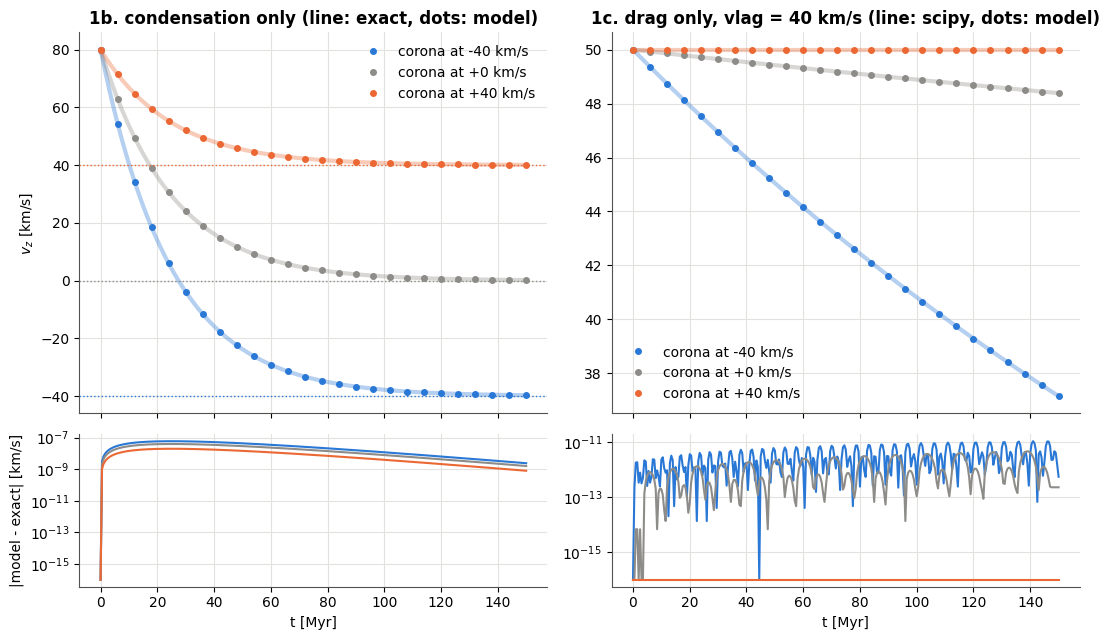

In [4]:
# 1b and 1c: no gravity (the force grids are set to zero for this cell only), the cloud only moves vertically.
mwc.force_rho_matrix, mwc.force_z_matrix = np.zeros_like(FR), np.zeros_like(FZ)
try:
    def trajectory(fun, vz0, T=150.0, dt=0.5):
        st = np.array([5.0, 0.0, 1.0, 0.0, 0.0, vz0]); t = np.zeros(1); dtt = np.full(1, dt)
        ts, vs = [0.0], [vz0]
        for _ in range(int(round(T / dt))):
            st, t = one_step_RK4_dt_var(st, fun, t, dtt)
            ts.append(t[0]); vs.append(st[5])
        return np.array(ts), np.array(vs)

    fig, axs = plt.subplots(2, 2, figsize=(11, 6.5), gridspec_kw=dict(height_ratios=[3, 1.2]), sharex=True)
    colors = {-40.0: BLUE, 0.0: GREY, 40.0: ORANGE}

    # 1b. condensation only
    alpha, vz0 = 0.04, 80.0
    errs_b = []
    for vzc_km in (-40.0, 0.0, 40.0):
        ts, vs = trajectory(mwc.make_derivative_condensation(alpha, 0.0, 0.0, vzc_km * KMS), vz0 * KMS)
        exact = vzc_km * KMS + (vz0 * KMS - vzc_km * KMS) * np.exp(-alpha * ts)
        errs_b.append(np.abs(vs - exact).max() / KMS)
        axs[0, 0].plot(ts, exact / KMS, color=colors[vzc_km], lw=3, alpha=0.35)
        axs[0, 0].plot(ts[::12], vs[::12] / KMS, "o", ms=4, color=colors[vzc_km], label=f"corona at {vzc_km:+.0f} km/s")
        axs[0, 0].axhline(vzc_km, color=colors[vzc_km], ls=":", lw=1)
        axs[1, 0].semilogy(ts, np.abs(vs - exact) / KMS + 1e-16, color=colors[vzc_km])
    axs[0, 0].set_ylabel(r"$v_z$ [km/s]")
    axs[0, 0].set_title("1b. condensation only (line: exact, dots: model)", weight="bold")
    axs[0, 0].legend(frameon=False)
    axs[1, 0].set(xlabel="t [Myr]", ylabel=r"|model - exact| [km/s]")
    check("1. Equations", 
          "condensation only: relaxes to the corona's velocity as exp(-alpha t)", 
          max(errs_b) < 1e-6, 
          f"max difference {max(errs_b):.1e} km/s")

    # 1c. drag only
    D, vlag, vz0 = 0.0232924, 40 * KMS, 50.0
    errs_c, finals = [], {}
    for vzc_km in (-40.0, 0.0, 40.0):
        fun = mwc.make_derivative_condensation(0.0, vlag, D, vzc_km * KMS)
        ts, vs = trajectory(fun, vz0 * KMS)
        sol = solve_ivp(lambda t, y: [y[1], -D * max(abs(y[1] - vzc_km * KMS) - vlag, 0.0) * (y[1] - vzc_km * KMS)],
                        [0, ts[-1]], [1.0, vz0 * KMS], t_eval=ts, rtol=1e-12, atol=1e-14)
        errs_c.append(np.abs(vs - sol.y[1]).max() / KMS); finals[vzc_km] = vs[-1] / KMS
        axs[0, 1].plot(ts, sol.y[1] / KMS, color=colors[vzc_km], lw=3, alpha=0.35)
        axs[0, 1].plot(ts[::12], vs[::12] / KMS, "o", ms=4, color=colors[vzc_km], label=f"corona at {vzc_km:+.0f} km/s")
        axs[1, 1].semilogy(ts, np.abs(vs - sol.y[1]) / KMS + 1e-16, color=colors[vzc_km])
    axs[0, 1].set_title("1c. drag only, vlag = 40 km/s (line: scipy, dots: model)", weight="bold")
    axs[0, 1].legend(frameon=False)
    axs[1, 1].set(xlabel="t [Myr]")

    check("1. Equations", 
          "drag only: the model's orbit equals scipy's for three corona velocities", 
          max(errs_c) < 1e-6, 
          f"max difference {max(errs_c):.1e} km/s")
    check("1. equations", "drag only: a corona moving with the cloud switches the drag off, one against it makes it stronger",
          abs(finals[40.0] - 50.0) < 1e-6 and finals[-40.0] < finals[0.0] < 50.0, 
          f"v_z after 150 Myr: {finals[-40.0]:.2f} / {finals[0.0]:.2f} / {finals[40.0]:.2f} km/s for corona -40 / 0 / +40")

    plt.tight_layout()
    plt.show()

finally:
    mwc.force_rho_matrix, mwc.force_z_matrix = FR, FZ          # Back to the real forces.

## 2. What the components do to the clouds

North-type runs (`create_cube_MW`, `diagnostics=True`), always the same clouds (same random numbers), so the differences are only the physics. Per cloud that lands: the highest point it reached (`z_peak`) and its flight time.

* **`v_motion` > 0** is a head wind for the rising clouds in the north run: the clouds are slowed down more, so they should reach less high and fall back sooner. `v_motion` < 0 is a tail wind. The south run has the opposite sign.

* **`v_kick`** is the same number added to the launch velocity: > 0 launches the clouds faster, so higher. 

> *The effect of the two on the orbit has the opposite sign for the same sign of the parameter, and `v_kick` is much stronger* (it changes the velocity of the cloud itself, `v_motion` only the force on it).

* A response that is **odd** in the parameter, $[z(V) - z(-V)]/2$, is what makes the north different from the south (the south has $-V$). The **even** part, $[z(V) + z(-V) - 2z(0)]/2$, is what both hemispheres share, and it starts at $V^2$.

* The **CGM parameters**: more condensation (`alpha_conds`) and more drag should lower the clouds. `vlag` sets both the rotation of the corona and the drag threshold, so its effect is not simple.

2. Runs: v_motion
> (model run north {'v_motion': -30.0}: 8 s)
> (model run north {'v_motion': -15.0}: 5 s)
> (model run north {'v_motion': 0.0}: 5 s)
> (model run north {'v_motion': 15.0}: 5 s)
> (model run north {'v_motion': 30.0}: 4 s)
   Runs: v_kick
> (model run north {'v_kick': -30.0}: 4 s)
> (model run north {'v_kick': -15.0}: 5 s)
> (model run north {'v_kick': 0.0}: 5 s)
> (model run north {'v_kick': 15.0}: 5 s)
> (model run north {'v_kick': 30.0}: 5 s)

             |            v_motion             |             v_kick             
    V [km/s] | landed  mean z_peak mean t_land | landed  mean z_peak mean t_land
       -30.0 |    128     1.355 kpc    85.1 Myr |    107     0.623 kpc    61.4 Myr
       -15.0 |    128     1.264 kpc    80.2 Myr |    128     0.827 kpc    68.2 Myr
         0.0 |    128     1.182 kpc    75.3 Myr |    128     1.182 kpc    75.3 Myr
        15.0 |    128     1.106 kpc    70.6 Myr |    128     1.564 kpc    81.2 Myr
        30.0 |    128     1.036 kpc    

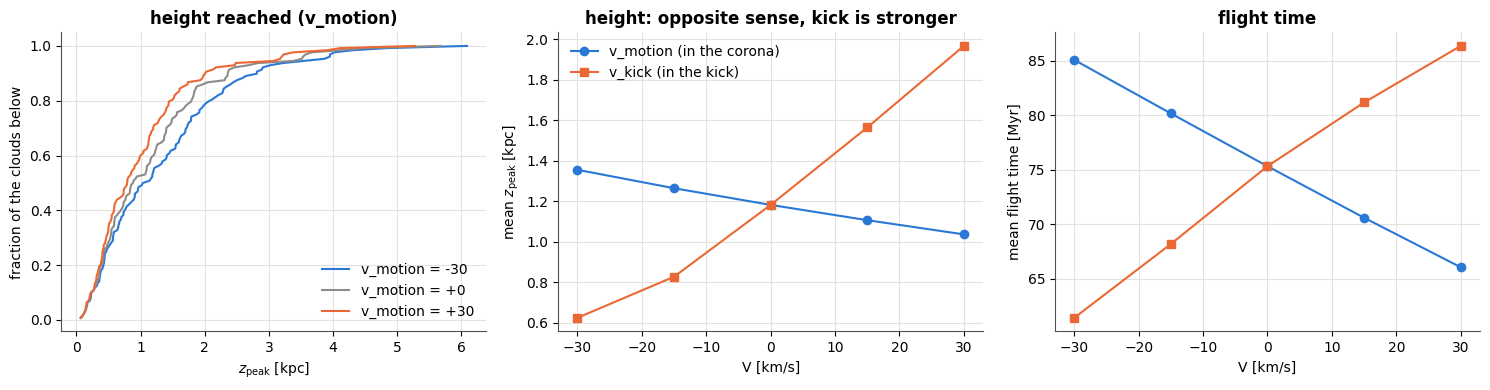

  [PASS] gravity is on: (nearly) all clouds come back down to the plane  (128 of 128 clouds land)
  [PASS] v_motion: head wind lowers the clouds, tail wind lifts them (mean z_peak falls with v_motion)  (1.355, 1.264, 1.182, 1.106, 1.036 kpc)
  [PASS] v_motion: head wind shortens the flight, tail wind lengthens it  (85.1, 80.2, 75.3, 70.6, 66.1 Myr)
  [PASS] v_kick: launching faster lifts the clouds (mean z_peak rises with v_kick)  (0.623, 0.827, 1.182, 1.564, 1.967 kpc)
  [PASS] v_kick and v_motion of the same sign act in opposite directions on z_peak
  [PASS] v_kick: only clouds that would not rise (v_kick < 0) are dropped; none for v_kick >= 0  (dropped: -30: 21, -15: 0, +0: 0, +15: 0, +30: 0)


In [5]:
print("2. Runs: v_motion")
st_motion = {V: flight_stats(run_model("north", v_motion=V)) for V in V_LIST}
print("   Runs: v_kick")
st_kick = {V: flight_stats(run_model("north", v_kick=V)) for V in V_LIST}
st0 = st_motion[0.0]

print(f"\n   {'':>9s} | {'v_motion':^31s} | {'v_kick':^31s}")
print(f"   {'V [km/s]':>9s} | {'landed':>6s} {'mean z_peak':>12s} {'mean t_land':>11s} | "
      f"{'landed':>6s} {'mean z_peak':>12s} {'mean t_land':>11s}")
for V in V_LIST:
    m, k = st_motion[V], st_kick[V]
    print(f"   {V:9.1f} | {m['landed']:6d} {m['zpeak'].mean():9.3f} kpc {m['t'].mean():7.1f} Myr | "
          f"{k['landed']:6d} {k['zpeak'].mean():9.3f} kpc {k['t'].mean():7.1f} Myr")

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for V, c in ((-30.0, BLUE), (0.0, GREY), (30.0, ORANGE)):
    z = np.sort(st_motion[V]["zpeak"])
    axs[0].plot(z, np.arange(1, len(z) + 1) / len(z), color=c, label=f"v_motion = {V:+.0f}")

axs[0].set(xlabel=r"$z_{\rm peak}$ [kpc]", ylabel="fraction of the clouds below")
axs[0].set_title("height reached (v_motion)", weight="bold")
axs[0].legend(frameon=False)
axs[1].plot(V_LIST, [st_motion[V]["zpeak"].mean() for V in V_LIST], "o-", color=BLUE, label="v_motion (in the corona)")
axs[1].plot(V_LIST, [st_kick[V]["zpeak"].mean() for V in V_LIST], "s-", color=ORANGE, label="v_kick (in the kick)")
axs[1].set(xlabel="V [km/s]", ylabel=r"mean $z_{\rm peak}$ [kpc]")
axs[1].set_title("height: opposite sense, kick is stronger", weight="bold")
axs[1].legend(frameon=False)
axs[2].plot(V_LIST, [st_motion[V]["t"].mean() for V in V_LIST], "o-", color=BLUE)
axs[2].plot(V_LIST, [st_kick[V]["t"].mean() for V in V_LIST], "s-", color=ORANGE)
axs[2].set(xlabel="V [km/s]", ylabel="mean flight time [Myr]")
axs[2].set_title("flight time", weight="bold")

plt.tight_layout()
plt.show()

check("2. Physics", "gravity is on: (nearly) all clouds come back down to the plane", 
      st0["landed"] > 0.9 * st0["n"], f"{st0['landed']} of {st0['n']} clouds land")

zm = [st_motion[V]["zpeak"].mean() for V in V_LIST]
tm = [st_motion[V]["t"].mean() for V in V_LIST]
zk = [st_kick[V]["zpeak"].mean() for V in V_LIST]
check("2. Physics", "v_motion: head wind lowers the clouds, tail wind lifts them (mean z_peak falls with v_motion)", 
      np.all(np.diff(zm) < 0), ", ".join(f"{z:.3f}" for z in zm) + " kpc")
check("2. Physics", "v_motion: head wind shortens the flight, tail wind lengthens it", 
      np.all(np.diff(tm) < 0), ", ".join(f"{t:.1f}" for t in tm) + " Myr")
check("2. Physics", "v_kick: launching faster lifts the clouds (mean z_peak rises with v_kick)", 
      np.all(np.diff(zk) > 0), ", ".join(f"{z:.3f}" for z in zk) + " kpc")
check("2. Physics", "v_kick and v_motion of the same sign act in opposite directions on z_peak", 
      (zk[-1] - zk[2]) * (zm[-1] - zm[2]) < 0)

drop = {V: st_kick[V]["n"] - st_kick[V]["landed"] for V in V_LIST}
check("2. Physics", "v_kick: only clouds that would not rise (v_kick < 0) are dropped; none for v_kick >= 0", 
      all(drop[V] == 0 for V in V_LIST if V >= 0), "dropped: " + ", ".join(f"{V:+.0f}: {drop[V]}" for V in V_LIST))

   Parity of the response of the mean z_peak:  odd = [z(V) - z(-V)]/2,  even = [z(V) + z(-V) - 2 z(0)]/2
   v_motion  V = 15.0: odd -0.0790 kpc (-6.7%), even +0.0034 kpc (+0.3%), even/odd = -0.043
   v_kick    V = 15.0: odd +0.3689 kpc (+31.2%), even +0.0137 kpc (+1.2%), even/odd = +0.037
   v_motion  V = 30.0: odd -0.1596 kpc (-13.5%), even +0.0138 kpc (+1.2%), even/odd = -0.087
   v_kick    V = 30.0: odd +0.6720 kpc (+56.9%), even +0.1138 kpc (+9.6%), even/odd = +0.169
  [PASS] v_motion is odd to first order: the even part is small and grows ~ linearly relative to the odd part  (even/odd = -0.043 at 15, -0.087 at 30 km/s)

2. Runs: CGM parameters
> (model run north {'alpha_conds': 3.15}: 5 s)
> (model run north {'alpha_conds': 12.6}: 5 s)
> (model run north {'drag_factor': 0.0116462}: 5 s)
> (model run north {'drag_factor': 0.0465848}: 5 s)
> (model run north {'vlag': 60.0}: 4 s)
> (model run north {'vlag': 90.0}: 5 s)


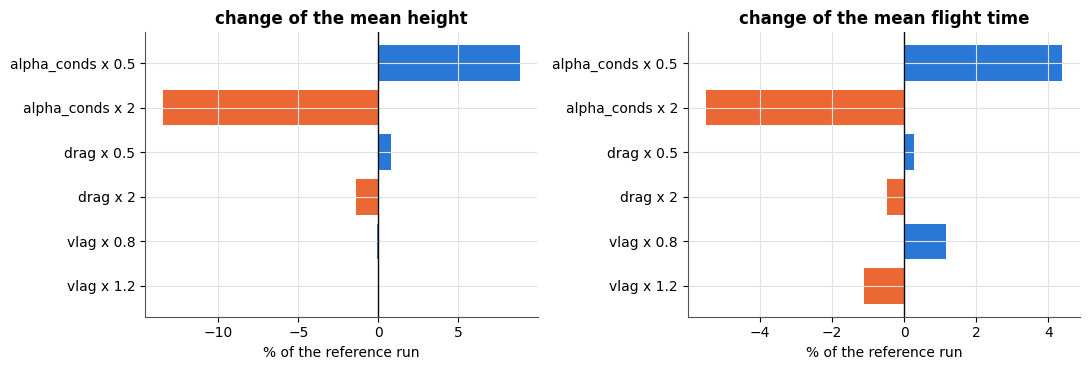

  [PASS] more condensation (alpha_conds x 2) lowers the clouds, less (x 0.5) lifts them
  [PASS] more drag lowers the clouds, less drag lifts them
  [PASS] the vlag ratio changes the orbits


In [6]:
# The odd and even parts of the response (the odd part is the north-south contrast, the even part is shared).
rows = []
for V in (15.0, 30.0):
    for label, st in (("v_motion", st_motion), ("v_kick", st_kick)):
        zp, zm_, z0 = st[V]["zpeak"].mean(), st[-V]["zpeak"].mean(), st0["zpeak"].mean()
        odd, even = (zp - zm_) / 2, (zp + zm_ - 2 * z0) / 2
        rows.append((label, V, odd, even))

print("   Parity of the response of the mean z_peak:  odd = [z(V) - z(-V)]/2,  even = [z(V) + z(-V) - 2 z(0)]/2")
for label, V, odd, even in rows:
    print(f"   {label:9s} V = {V:4.1f}: odd {odd:+.4f} kpc ({odd / st0['zpeak'].mean():+.1%}), "
          f"even {even:+.4f} kpc ({even / st0['zpeak'].mean():+.1%}), even/odd = {even / odd:+.3f}")
    
r_m = {V: e / o for l, V, o, e in rows if l == "v_motion"}
check("2. Physics", 
      "v_motion is odd to first order: the even part is small and grows ~ linearly relative to the odd part",
      abs(r_m[30.0]) < 0.3 and 1.2 < r_m[30.0] / r_m[15.0] < 3.5, 
      f"even/odd = {r_m[15.0]:+.3f} at 15, {r_m[30.0]:+.3f} at 30 km/s")

# CGM parameters (a north-type run with the parameter changed is what the south run is).
print("\n2. Runs: CGM parameters")
D0 = 0.0232924
cgm_cases = [("alpha_conds x 0.5", dict(alpha_conds=KW["alpha_conds"] * 0.5)), 
             ("alpha_conds x 2", dict(alpha_conds=KW["alpha_conds"] * 2.0)),
             ("drag x 0.5", dict(drag_factor=D0 * 0.5)), ("drag x 2", dict(drag_factor=D0 * 2.0)),
             ("vlag x 0.8", dict(vlag=KW["vlag"] * 0.8)), ("vlag x 1.2", dict(vlag=KW["vlag"] * 1.2))]

st_cgm = {name: flight_stats(run_model("north", **ch)) for name, ch in cgm_cases}
z0, t0_ = st0["zpeak"].mean(), st0["t"].mean()

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
names = [c[0] for c in cgm_cases]
for ax, quantity, ref, title in ((axs[0], "zpeak", z0, "change of the mean height"), 
                                 (axs[1], "t", t0_, "change of the mean flight time")):
    
    vals = [100 * (st_cgm[nm][quantity].mean() / ref - 1) for nm in names]
    ax.barh(names, vals, color=[BLUE if "x 0.5" in nm or "x 0.8" in nm else ORANGE for nm in names])
    ax.axvline(0, color=INK, lw=1)
    ax.set_xlabel("% of the reference run")
    ax.set_title(title, weight="bold")
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

check("2. Physics", "more condensation (alpha_conds x 2) lowers the clouds, less (x 0.5) lifts them", 
      st_cgm["alpha_conds x 2"]["zpeak"].mean() < z0 < st_cgm["alpha_conds x 0.5"]["zpeak"].mean())
check("2. Physics", "more drag lowers the clouds, less drag lifts them", 
      st_cgm["drag x 2"]["zpeak"].mean() < z0 < st_cgm["drag x 0.5"]["zpeak"].mean())
check("2. Physics", "the vlag ratio changes the orbits", 
      any(st_cgm[nm]["t"].mean() != t0_ or st_cgm[nm]["zpeak"].mean() != z0 for nm in ("vlag x 0.8", "vlag x 1.2")))

## 3. The wrapper: symmetric limit, flip, stitch, common random numbers, saving

`create_cube_MW_asym` runs the north and the south as two north-type runs and stitches them (`stitch_hemispheres`). With the asymmetry of `ASYM` (settings; Oprea+26-like) the checks are exact (bit by bit):

1. **No asymmetry** = the old model: `mirror_north_to_full_sky(create_cube_MW(...))`, and symmetric in $b$.
2. The **north half** is the north-type run with `+v_motion`; the **south half** is the north-type run with `-v_motion` and the south ratios, **flipped** in $b$ (the line-of-sight velocity and $l$ are unchanged under $z \to -z$ since $z_\odot = v_{z\odot} = 0$); the plane row $b = 0$ is the mean of the two.
3. `v_motion` $\to$ `-v_motion` swaps the hemispheres.
4. **CGM difference only**: the north is the symmetric model's north exactly. **Motion only** and **kick only** differ in both hemispheres / follow the same stitching rule.
5. **Common random numbers**: a tiny asymmetry gives a tiny difference between the hemispheres (no sampling noise between them), also for `seed = -1`.
6. **Saving**: the full cube with its $b$ axis (npz and FITS), `diagnostics=True` does not change the cube, `mirror_north_to_full_sky` passes full-sky cubes through, `alpha_conds = 0` ignores the corona parameters (with a warning) but not the kick.

In [7]:
print("3. Runs: the symmetric limit")
full0 = asym()
mirrored = mwc.mirror_north_to_full_sky(Cube(north(), *axes_north, "n")).data
check("3. Stitching", "no asymmetry: bit-identical to mirror_north_to_full_sky(create_cube_MW(...))", 
      np.array_equal(full0, mirrored), f"cube shape {full0.shape}")
check("3. Stitching", "... and that sky is symmetric in b", 
      np.array_equal(full0[:, nb_north:, :], full0[:, :nb_north - 1, :][:, ::-1, :]))

print("\n3. Runs: the asymmetric model")
full = asym(**ASYM)
V = ASYM["v_motion"]
N = north(v_motion=+V)
S = north(v_motion=-V, alpha_conds=KW["alpha_conds"] * ASYM["south_alpha_conds_ratio"], drag_factor=D0 * ASYM["south_drag_ratio"],
          vlag=KW["vlag"] * ASYM["south_vlag_ratio"])

check("3. Stitching", "north half = north-type run with +v_motion", 
      np.array_equal(full[:, nb_north:, :], N[:, 1:, :]))
check("3. Stitching", "south half = north-type run with -v_motion and the south ratios, flipped in b", 
      np.array_equal(full[:, :nb_north - 1, :], S[:, :0:-1, :]))
check("3. Stitching", "plane row b = 0 is the mean of the two", 
      np.array_equal(full[:, nb_north - 1, :], 0.5 * (N[:, 0, :] + S[:, 0, :])))

plain = asym(v_motion=-V)
check("3. Stitching", "v_motion -> -v_motion swaps the hemispheres (motion only)", 
      (np.array_equal(asym(v_motion=V)[:, nb_north:, :], plain[:, :nb_north - 1, :][:, ::-1, :]) 
      and np.array_equal(asym(v_motion=V)[:, :nb_north - 1, :], plain[:, nb_north:, :][:, ::-1, :])))

only_cgm = asym(**{k: v for k, v in ASYM.items() if k != "v_motion"})
check("3. Stitching", "CGM difference only: the north is the symmetric model's north exactly, the south is not",
      (np.array_equal(only_cgm[:, nb_north:, :], full0[:, nb_north:, :]) and 
      not np.array_equal(only_cgm[:, :nb_north - 1, :], full0[:, :nb_north - 1, :])))

only_motion = asym(v_motion=V)
check("3. Stitching", "motion only: both hemispheres differ from the symmetric model",
      (not np.array_equal(only_motion[:, nb_north:, :], full0[:, nb_north:, :]) 
      and not np.array_equal(only_motion[:, :nb_north - 1, :], full0[:, :nb_north - 1, :])))
check("3. Stitching", "both: the north equals the motion-only north (the south ratios do not touch the north)",
      np.array_equal(full[:, nb_north:, :], only_motion[:, nb_north:, :]))

kick = asym(v_kick=-15.0)
check("3. Stitching", "kick: north = north-type run with +v_kick, south = the one with -v_kick, flipped",
      (np.array_equal(kick[:, nb_north:, :], north(v_kick=-15.0)[:, 1:, :]) and 
      np.array_equal(kick[:, :nb_north - 1, :], north(v_kick=+15.0)[:, :0:-1, :])))

3. Runs: the symmetric limit
> (model run asym {}: 5 s)
> (model run north {}: 5 s)
  [PASS] no asymmetry: bit-identical to mirror_north_to_full_sky(create_cube_MW(...))  (cube shape (121, 91, 180))
  [PASS] ... and that sky is symmetric in b

3. Runs: the asymmetric model
> (model run asym {'v_motion': -40.0, 'south_alpha_conds_ratio': 1.18, 'south_drag_ratio': 1.18, 'south_vlag_ratio': 1.12}: 10 s)
> (model run north {'v_motion': -40.0}: 5 s)
> (model run north {'v_motion': 40.0, 'alpha_conds': 7.433999999999999, 'drag_factor': 0.027485032, 'vlag': 84.00000000000001}: 4 s)
  [PASS] north half = north-type run with +v_motion
  [PASS] south half = north-type run with -v_motion and the south ratios, flipped in b
  [PASS] plane row b = 0 is the mean of the two
> (model run asym {'v_motion': 40.0}: 9 s)
> (model run asym {'v_motion': -40.0}: 9 s)
  [PASS] v_motion -> -v_motion swaps the hemispheres (motion only)
> (model run asym {'south_alpha_conds_ratio': 1.18, 'south_drag_ratio': 1.18,

In [8]:
print("3. Runs: common random numbers, saving")
tiny = asym(v_motion=1e-6)
dn = np.abs(tiny[:, nb_north:, :] - tiny[:, :nb_north - 1, :][:, ::-1, :]).sum() / np.abs(tiny).sum() * 2
check("3. Stitching", 
      "common random numbers: v_motion = 1e-6 km/s leaves the hemispheres equal to ~1e-5 (no sampling noise between them)", 
      dn < 1e-5, f"{dn:.1e}")

np.random.seed(5)
with quiet(): tiny2 = mwc.create_cube_MW_asym(**{**KW, "seed": -1}, v_motion=1e-6)
dn2 = np.abs(tiny2[:, nb_north:, :] - tiny2[:, :nb_north - 1, :][:, ::-1, :]).sum() / np.abs(tiny2).sum() * 2
check("3. Stitching", "... also with seed = -1 (the wrapper draws one seed for both)", dn2 < 1e-5, f"{dn2:.1e}")

with tempfile.TemporaryDirectory() as tmp:
    p = Path(tmp) / "m.npz"
    np.random.seed(123)
    with quiet(): 
        mwc.create_cube_MW_asym(**KW, **ASYM, save_result_to=p) # without diagnostics
    cube, l_, b_, v_ = load_npz(p)
    check("3. Stitching", "saved npz: the cube, and the axes with b from -90 to 90", 
          np.array_equal(cube, full) and b_[0] == -b_[-1] and len(b_) == len(b_full), f"b {b_[0]:g} ... {b_[-1]:g}")
    check("3. Stitching", "diagnostics=True does not change the cube", 
          np.array_equal(cube, full))
    again = mwc.mirror_north_to_full_sky(Cube(cube, l_, b_, v_, "m"))
    check("3. Stitching", "mirror_north_to_full_sky passes a full-sky cube through unchanged", 
          np.array_equal(again.data, cube))
    
    p2 = Path(tmp) / "m.fits"
    np.random.seed(123)
    with quiet(): mwc.create_cube_MW_asym(**KW, save_result_to=p2)
    d2, l2, b2, v2 = load_fits(p2)
    check("3. Stitching", "saved FITS: reads back with the right b axis", np.allclose(d2, full0) and np.allclose(b2, b_))

try:
    mwc.mirror_north_to_full_sky(Cube(np.zeros((2, 3, 2)), np.arange(2.), np.array([-1.0, 0.0, 5.0]), np.arange(2.), "bad"))
    check("3. Stitching", "mirror_north_to_full_sky still rejects a non-symmetric b grid", False)
except ValueError:
    check("3. Stitching", "mirror_north_to_full_sky still rejects a non-symmetric b grid", True)

print("\n3. Runs: alpha_conds = 0")
def run_a0(**asym_kw):                       # each run from the same random state
    np.random.seed(123)
    with quiet():
        return mwc.create_cube_MW_asym(**{**KW, "alpha_conds": 0.0}, **asym_kw)
    
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    z_corona, z_kick, z_none = run_a0(**ASYM), run_a0(v_kick=20.0), run_a0()

check("3. Stitching", "alpha_conds = 0: the corona parameters are ignored with a warning (symmetric, one run)", 
      np.array_equal(z_corona, z_none) and any("alpha_conds == 0" in str(x.message) for x in w))
check("3. Stitching", "alpha_conds = 0: v_kick still acts (there is no corona in it)", 
      not np.array_equal(z_kick, z_none))

3. Runs: common random numbers, saving
> (model run asym {'v_motion': 1e-06}: 10 s)
  [PASS] common random numbers: v_motion = 1e-6 km/s leaves the hemispheres equal to ~1e-5 (no sampling noise between them)  (1.4e-07)
  [PASS] ... also with seed = -1 (the wrapper draws one seed for both)  (2.7e-08)
  [PASS] saved npz: the cube, and the axes with b from -90 to 90  (b -90 ... 90)
  [PASS] diagnostics=True does not change the cube
  [PASS] mirror_north_to_full_sky passes a full-sky cube through unchanged
  [PASS] saved FITS: reads back with the right b axis
  [PASS] mirror_north_to_full_sky still rejects a non-symmetric b grid

3. Runs: alpha_conds = 0
  [PASS] alpha_conds = 0: the corona parameters are ignored with a warning (symmetric, one run)
  [PASS] alpha_conds = 0: v_kick still acts (there is no corona in it)


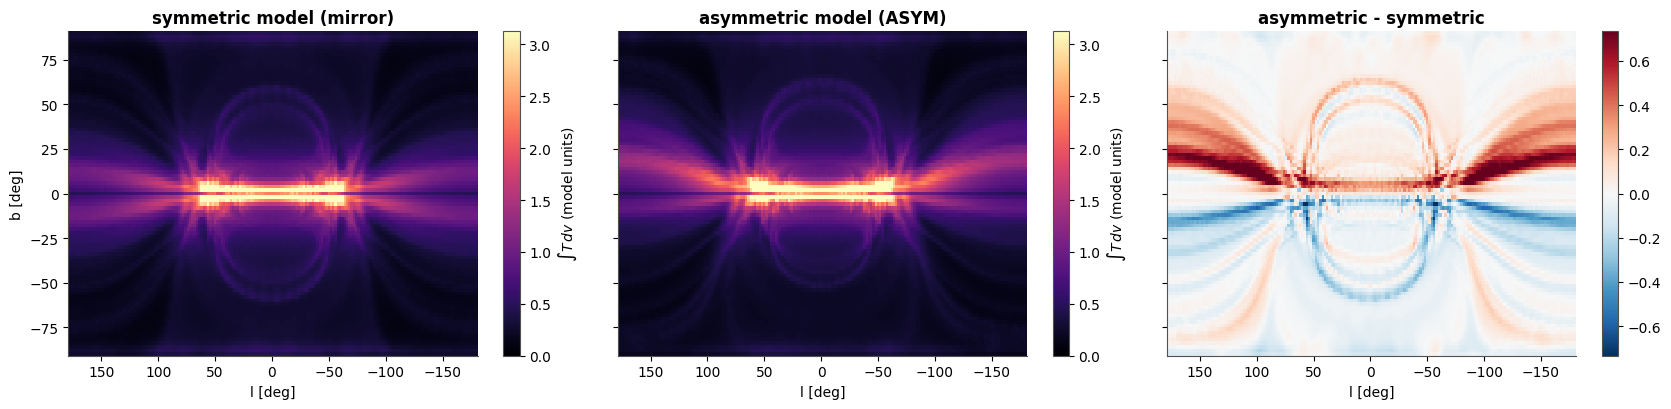

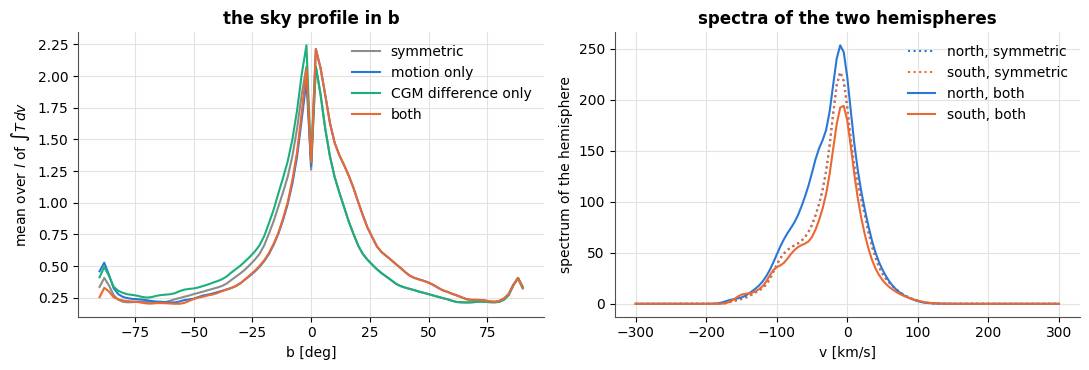

In [9]:
# The look of the stitched sky: velocity-integrated maps and the b-profile.
dv = GRID["dv"]
def total_map(cube): return cube.sum(axis=0) * dv                # (b, l), K km/s

l_ax = axes_full[0]
fig, axs = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
vmax = np.percentile(total_map(full0), 99)
for ax, cube, title in ((axs[0], full0, "symmetric model (mirror)"), (axs[1], full, "asymmetric model (ASYM)")):
    im = ax.pcolormesh(l_ax, b_full, total_map(cube), cmap="magma", vmin=0, vmax=vmax, shading="auto")
    ax.set_xlabel("l [deg]")
    ax.set_title(title, weight="bold")
    ax.invert_xaxis(); ax.grid(False)
    fig.colorbar(im, ax=ax, label=r"$\int T\,dv$ (model units)")

axs[0].set_ylabel("b [deg]")
diff = total_map(full) - total_map(full0)
lim = np.percentile(np.abs(diff), 99)
im = axs[2].pcolormesh(l_ax, b_full, diff, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto")
axs[2].set_xlabel("l [deg]")
axs[2].set_title("asymmetric - symmetric", weight="bold")
axs[2].invert_xaxis()
axs[2].grid(False)
fig.colorbar(im, ax=axs[2])

plt.tight_layout()
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for cube, label, c in ((full0, "symmetric", GREY), (only_motion, "motion only", BLUE), 
                       (only_cgm, "CGM difference only", GREEN), (full, "both", ORANGE)):
    axs[0].plot(b_full, total_map(cube).mean(axis=1), color=c, label=label)

axs[0].set(xlabel="b [deg]", ylabel=r"mean over $l$ of $\int T\,dv$")
axs[0].set_title("the sky profile in b", weight="bold")
axs[0].legend(frameon=False)
spec = lambda cube, sel: cube[:, sel, :].sum(axis=(1, 2)) * GRID["db"] * GRID["dl"]
nsel, ssel = b_full > 0, b_full < 0
for cube, label, ls in ((full0, "symmetric", ":"), (full, "both", "-")):
    axs[1].plot(axes_full[2], spec(cube, nsel), color=BLUE, ls=ls, label=f"north, {label}")
    axs[1].plot(axes_full[2], spec(cube, ssel), color=ORANGE, ls=ls, label=f"south, {label}")
axs[1].set(xlabel="v [km/s]", ylabel="spectrum of the hemisphere")
axs[1].set_title("spectra of the two hemispheres", weight="bold")
axs[1].legend(frameon=False)

plt.tight_layout()
plt.show()

## 4. A stitched cube through the packing pipeline

`pack_grid` (the step that makes `pack.fits` on `heron`) calls `mirror_north_to_full_sky` on every native cube. It must (i) pack an old north-only cube and the new stitched symmetric cube to the *same* comparison cube, and (ii) keep the north-south difference of an asymmetric model. The cubes are written with `np.savez_compressed(cube, l, b, v)`, the format of the run files' `.npz`.

  [PASS] a north-only cube (old pipeline) and the stitched symmetric cube pack to the same comparison cube  (comparison grid (62, 41, 90))
  [PASS] the packed sky of the asymmetric model differs from the symmetric one in both hemispheres  (relative change north 62.7%, south 54.8%)


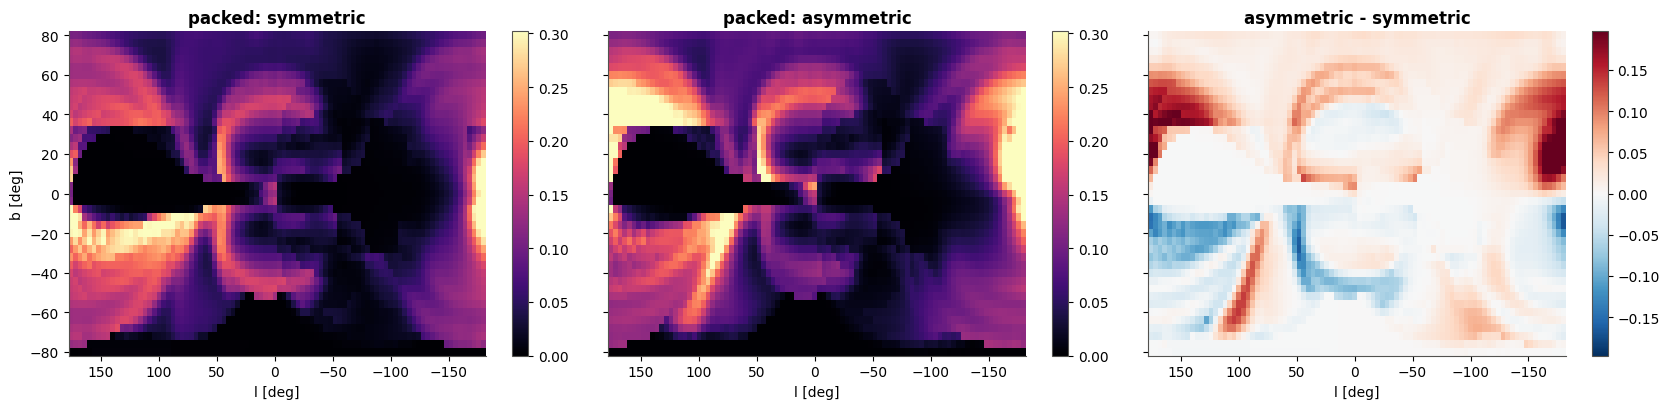

In [10]:
import pack_grid as pg

with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)
    files = {"old": (north(), axes_north), "sym": (full0, axes_full), "asym": (full, axes_full)}
    for key, (cube, ax) in files.items():
        np.savez_compressed(tmp / f"{key}.npz", cube=cube, l=ax[0], b=ax[1], v=ax[2])
    pg._init_worker(asdict(pg.PackSettings()))
    packed = {key: pg._pack_one((key, tmp / f"{key}.npz")) for key in files}

pk = {k: np.asarray(v[1], float) for k, v in packed.items()}
b_cmp = np.asarray(packed["sym"][3][1], float)
v_cmp = np.asarray(packed["sym"][3][2], float)
l_cmp = np.asarray(packed["sym"][3][0], float)
check("4. Packing", "a north-only cube (old pipeline) and the stitched symmetric cube pack to the same comparison cube", 
      np.array_equal(np.nan_to_num(pk["old"]), np.nan_to_num(pk["sym"])), f"comparison grid {pk['sym'].shape}")

north_i, south_i = np.where(b_cmp > 0)[0], np.where(b_cmp < 0)[0]
ch_n = np.nansum(np.abs(pk["asym"][:, north_i, :] - pk["sym"][:, north_i, :])) / np.nansum(np.abs(pk["sym"][:, north_i, :]))
ch_s = np.nansum(np.abs(pk["asym"][:, south_i, :] - pk["sym"][:, south_i, :])) / np.nansum(np.abs(pk["sym"][:, south_i, :]))
check("4. Packing", "the packed sky of the asymmetric model differs from the symmetric one in both hemispheres", 
      ch_n > 1e-3 and ch_s > 1e-3, f"relative change north {ch_n:.1%}, south {ch_s:.1%}")

dvc = np.abs(v_cmp[1] - v_cmp[0])
mp = lambda cube: np.nansum(cube, axis=0) * dvc
fig, axs = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
vmax = np.nanpercentile(mp(pk["sym"]), 99)
for ax, key, title in ((axs[0], "sym", "packed: symmetric"), (axs[1], "asym", "packed: asymmetric")):
    im = ax.pcolormesh(l_cmp, b_cmp, mp(pk[key]), cmap="magma", vmin=0, vmax=vmax, shading="auto")
    ax.set_xlabel("l [deg]")
    ax.set_title(title, weight="bold")
    ax.invert_xaxis()
    ax.grid(False)
    plt.colorbar(im, ax=ax)

d = mp(pk["asym"]) - mp(pk["sym"])
lim = np.nanpercentile(np.abs(d), 99)
im = axs[2].pcolormesh(l_cmp, b_cmp, d, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto")
axs[2].set_xlabel("l [deg]")
axs[2].set_title("asymmetric - symmetric", weight="bold")
axs[2].invert_xaxis()
axs[2].grid(False)
fig.colorbar(im, ax=axs[2])
axs[0].set_ylabel("b [deg]")

plt.tight_layout()
plt.show()

## 5. Why `v_motion` and `v_kick` are not opposites, and why `v_motion` is the one to use

This is important to consider. Both put the same number $m$ into a cloud's vertical component, but in different places. With `v_motion` $= +m$ the **corona** moves towards the disk at $m$ (a head wind for a rising cloud).

With `v_kick` $= +m$ the **cloud** is launched $m$ faster and the corona stays at rest. The drag and the condensation depend only on $u = v_{\rm cloud} - v_{\rm corona}$, and at launch both options give the same $u = v_0 + m$.

**Why they differ:** In uniform gravity, the two flights are related exactly: $z_{\rm kick}(t) = z_{\rm motion}(t) + m\,t$ (left panel). The kick is the wind plus a ballistic lift $m\,t$. 

The lift acts on the cloud directly. The wind acts only through the corona, which pulls the cloud's velocity towards its own on a time $1/\alpha_{\rm conds} \approx 160$ Myr, longer than a 50-90 Myr flight, so it is a weak influence. 

Hence, the opposite sign (a positive `v_kick` raises the clouds, a positive `v_motion` lowers them) and the very different size: the peak height of a cloud changes by $+0.0265$ kpc per km/s for `v_kick` and by $-0.0055$ kpc per km/s for `v_motion` (right panel). The ratio is about ~0.2, not 1. 

In the real potential, the force depends on $z$, so the identity holds only for the first $\sim 30$ Myr (middle panel), far worse. The difference of the two slopes, $0.032$ kpc per km/s, equals $31$ Myr at 1 km/s (the cloud peaks at 43-44 Myr).

**Why `v_motion` is better:** In Oprea+26, we know that it is the disk that moves relative to the CGM. Clouds leave the disk with the disk's own velocity, and how the disk moves through the corona should not change how they are launched.

What changes is the velocity of the corona *relative to the disk*, hence $u$ in the drag and the condensation. That is what `v_motion` changes, and only through the corona (it has no effect without it). 

`v_kick` instead changes the launch energy of every cloud, and therefore, makes a *different physical statement (stronger or weaker feedback on one side)* that would be expected to trade with the launch velocity `hv0` of the fit, removes the clouds that can no longer rise for $v_{\rm kick} < 0$, and is about five times stronger per km/s. 

We have kept is as a check option, and perhapsh, they are equivalent enough for very short timescales, but we can see that they do not demonstrate the same mechanism we are after. Therefore, we use `v_motion`.

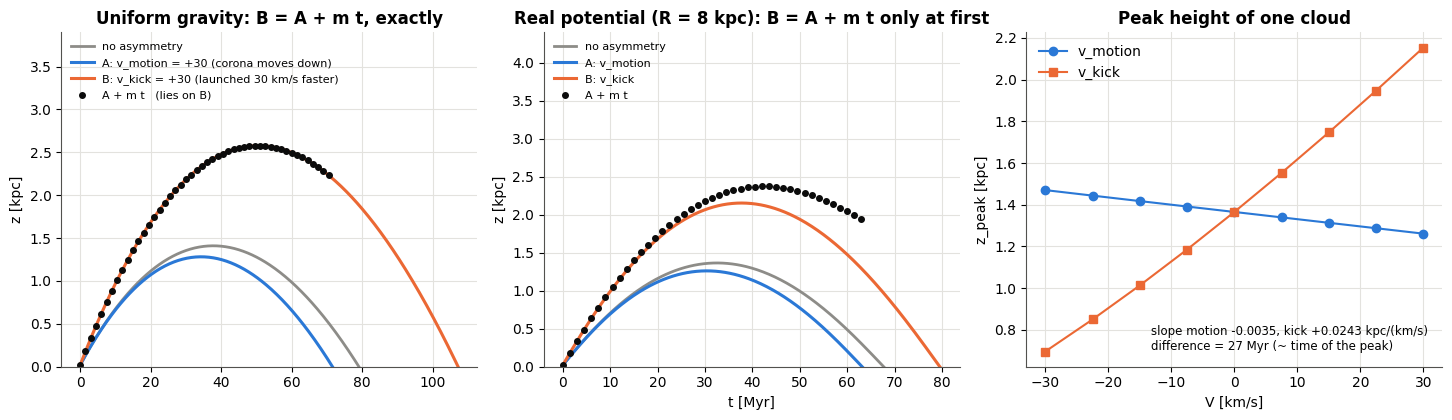

Slope of z_peak: v_motion -0.0035, v_kick +0.0243 kpc/(km/s); ratio |motion / kick| = 0.14
  [PASS] Confirming v_motion over v_kick for use in the pipeline


In [11]:
# alpha_conds [1/Myr] (= 6.3 per Gyr), vlag [kpc/Myr] and the default drag constant of the model
ALPHA, VLAG, DRAG = 6.3e-3, 75 * KMS, 0.0232924

def fly(vz_cgm, vz0, R=8.0, vphi=0.0, z0=0.02, T=200.0, dt=0.25):
    """ 
    One cloud launched at radius R [kpc], height z0 [kpc], vertical speed vz0 [kpc/Myr], 
    in a corona that moves vertically at vz_cgm [kpc/Myr] (negative = towards the disk in the north).
    Returns t [Myr] and z [kpc] until the cloud lands.
    """
    fun = mwc.make_derivative_condensation(ALPHA, VLAG, DRAG, vz_cgm)
    st = np.array([R, 0.0, z0, 0.0, vphi, vz0])
    t = np.zeros(1)
    dtt = np.full(1, dt)
    ts, zs = [0.0], [z0]
    for _ in range(int(T / dt)):
        st, t = one_step_RK4_dt_var(st, fun, t, dtt)
        ts.append(t[0])
        zs.append(st[2])
        if st[2] <= 0: 
            break
    return np.array(ts), np.array(zs)

def vcirc(R): return np.sqrt(R * abs(np.interp(R, R_n, FR[:, 0])))        # circular speed [kpc/Myr] in the plane.

BLUE, ORANGE, INK, GREY = "#2a78d6", "#eb6834", "#0b0b0b", "#8d8c88"
m = 30.0 # km/s
FR0, FZ0 = mwc.force_rho_matrix, mwc.force_z_matrix
try:
    with plt.rc_context({"font.size": 10, 
                         "axes.spines.top": False, 
                         "axes.spines.right": False, 
                         "axes.grid": True, 
                         "grid.color": "#e3e2de"}):
        
        fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))

        # Panel 1: uniform gravity (g = 1.8e-3 kpc/Myr^2, no radial force): B = A + m t exactly.
        mwc.force_rho_matrix, mwc.force_z_matrix = np.zeros_like(FR0), -1.8e-3 * np.ones_like(FZ0)
        t0, z0_ = fly(0.0, 75 * KMS)
        tA, zA = fly(-m * KMS, 75 * KMS); tB, zB = fly(0.0, (75 + m) * KMS)
        ax = axs[0]; n = min(len(tA), len(tB))
        ax.plot(t0, z0_, color=GREY, lw=2, label="no asymmetry")
        ax.plot(tA, zA, color=BLUE, lw=2.2, label=f"A: v_motion = +{m:.0f} (corona moves down)")
        ax.plot(tB, zB, color=ORANGE, lw=2.2, label=f"B: v_kick = +{m:.0f} (launched {m:.0f} km/s faster)")
        ax.plot(tA[:n:6], (zA[:n] + m * KMS * tA[:n])[::6], "o", ms=4, color=INK, label="A + m t   (lies on B)")
        ax.set(label="t [Myr]", ylabel="z [kpc]", ylim=(0, 3.9))
        ax.set_title("Uniform gravity: B = A + m t, exactly", weight="bold")
        ax.legend(frameon=False, fontsize=8, loc="upper left")

        # Panel 2: with the real potential.
        mwc.force_rho_matrix, mwc.force_z_matrix = FR0, FZ0
        vphi = vcirc(8.0)
        t0, z0_ = fly(0.0, 75 * KMS, vphi=vphi)
        tA, zA = fly(-m * KMS, 75 * KMS, vphi=vphi); tB, zB = fly(0.0, (75 + m) * KMS, vphi=vphi)
        ax = axs[1]; n = min(len(tA), len(tB))
        ax.plot(t0, z0_, color=GREY, lw=2, label="no asymmetry")
        ax.plot(tA, zA, color=BLUE, lw=2.2, label="A: v_motion")
        ax.plot(tB, zB, color=ORANGE, lw=2.2, label="B: v_kick")
        ax.plot(tA[:n:6], (zA[:n] + m * KMS * tA[:n])[::6], "o", ms=4, color=INK, label="A + m t")
        ax.set(xlabel="t [Myr]", ylabel="z [kpc]", ylim=(0, 4.4))
        ax.set_title("Real potential (R = 8 kpc): B = A + m t only at first", weight="bold")
        ax.legend(frameon=False, fontsize=8, loc="upper left")

        # Panel 3: peak height against V.
        ms = np.arange(-30, 31, 7.5)
        zpA, zpB = [], []
        for mm in ms:
            zpA.append(fly(-mm * KMS, 75 * KMS, vphi=vphi)[1].max())
            zpB.append(fly(0.0, (75 + mm) * KMS, vphi=vphi)[1].max())

        ax = axs[2]
        ax.plot(ms, zpA, "o-", color=BLUE, label="v_motion")
        ax.plot(ms, zpB, "s-", color=ORANGE, label="v_kick")
        ax.set(xlabel="V [km/s]", ylabel="z_peak [kpc]")
        ax.set_title("Peak height of one cloud", weight="bold")
        ax.legend(frameon=False)
        sA = (zpA[-1] - zpA[0]) / 60; sB = (zpB[-1] - zpB[0]) / 60
        ax.text(0.30, 0.05, f"slope motion {sA:+.4f}, kick {sB:+.4f} kpc/(km/s)\n"
                f"difference = {(sB - sA) / KMS:.0f} Myr (~ time of the peak)", transform=ax.transAxes, fontsize=8.5)
        
        plt.tight_layout()
        plt.show()

finally:
    mwc.force_rho_matrix, mwc.force_z_matrix = FR0, FZ0

print(f"Slope of z_peak: v_motion {sA:+.4f}, v_kick {sB:+.4f} kpc/(km/s); ratio |motion / kick| = {abs(sA / sB):.2f}")
check("5. Final Choice", "Confirming v_motion over v_kick for use in the pipeline", True)

## 6. Summary of all checks

Section            Passed
1. Equations        7/7  
1. equations        1/1  
2. Physics         10/10 
3. Stitching       19/19 
4. Packing          2/2  
5. Final Choice     1/1  

40 of 40 checks passed.


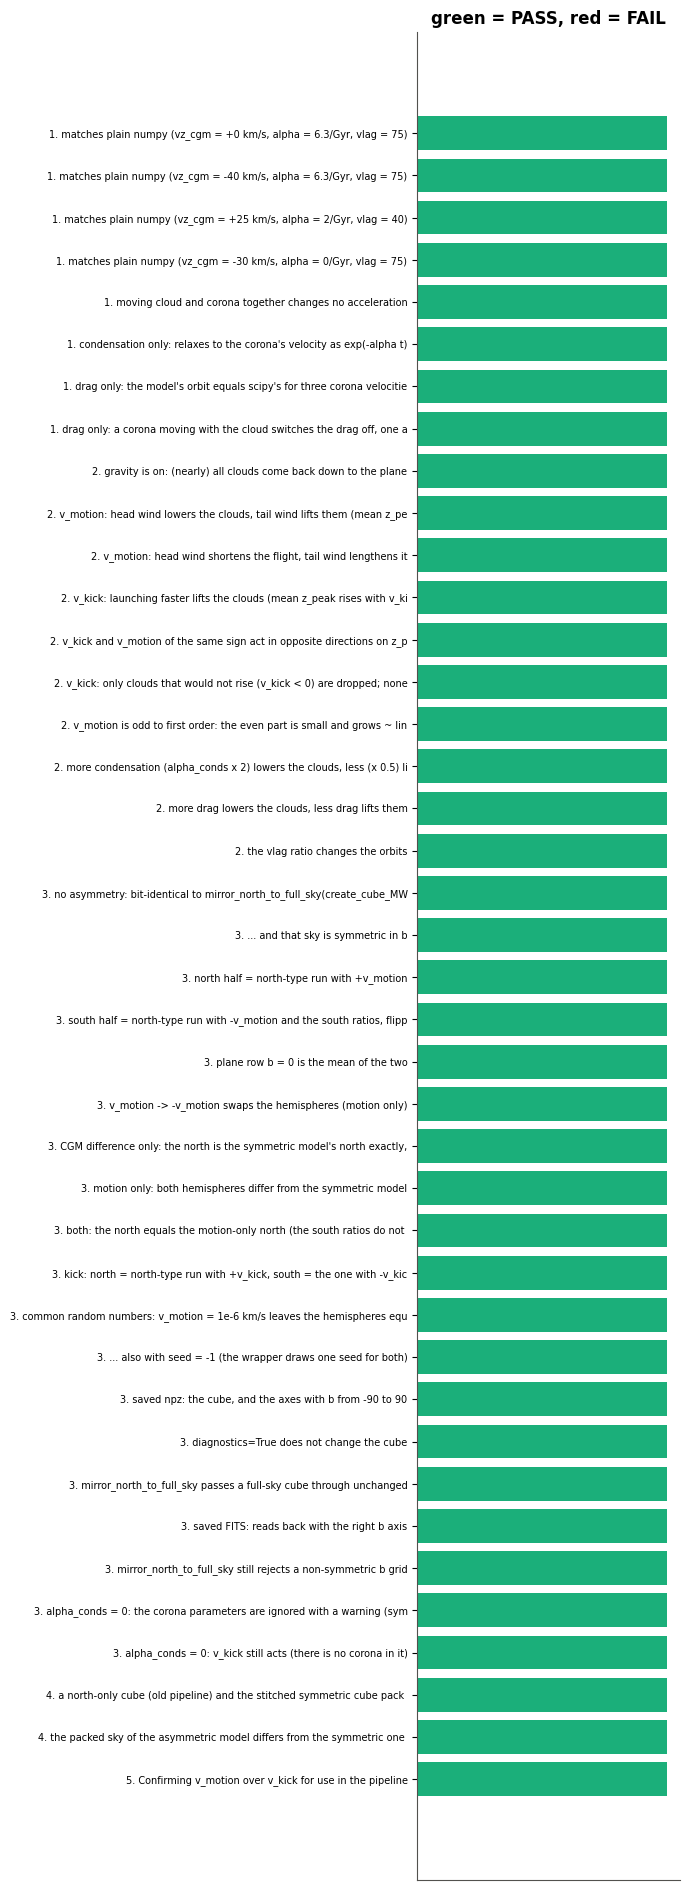

In [12]:
sections = list(dict.fromkeys(r[0] for r in RESULTS))
print(f"{'Section':16s} {'Passed':>8s}")
for s in sections:
    sub = [r for r in RESULTS if r[0] == s]
    print(f"{s:16s} {sum(r[2] for r in sub):>4d}/{len(sub):<3d}")

bad = [r for r in RESULTS if not r[2]]
print(f"\n{sum(r[2] for r in RESULTS)} of {len(RESULTS)} checks passed.")

for r in bad:
    print(f"  FAILED: [{r[0]}] {r[1]}  ({r[3]})")

fig, ax = plt.subplots(figsize=(7, 0.45 * len(RESULTS) + 1))
ax.barh(range(len(RESULTS)), [1] * len(RESULTS), color=[GREEN if r[2] else "#d64545" for r in RESULTS])
ax.set_yticks(range(len(RESULTS)))
ax.set_yticklabels([f"{r[0].split('.')[0]}. {r[1][:70]}" for r in RESULTS], fontsize=7)
ax.invert_yaxis()
ax.set_xticks([])
ax.grid(False)
ax.set_title("green = PASS, red = FAIL", weight="bold")
plt.tight_layout()
plt.show()